# Huấn luyện Ensemble Stacking đa lớp theo từng bước

Hai dataset dùng chung pipeline trong `src/`; notebook chỉ điều phối, không nhân bản thuật toán. Mặc định `DO_TRAIN=False`: đọc kết quả đã lưu, không train/ghi đè model. Để huấn luyện, chọn dataset, đặt OUT mới, đổi DO_TRAIN=True, Restart Kernel rồi Run All. Khi huấn luyện, tất cả bước đọc/làm sạch/split/fit đều chạy thật; tuning và fit có thể mất vài phút.

Phân biệt: M1/M2/M3 hiện là bộ thí nghiệm nhị phân; notebook này là thí nghiệm đa lớp riêng. Không dùng test để chọn tham số hoặc seed.

In [1]:
%matplotlib inline
from argparse import Namespace
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/train.py').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from dataset import read_sample
from features import FEATURES
from train import split_data, run_experiment

DO_TRAIN = False
DATASET = 'cicids2017'  # hoặc 'insdn'
SEED, CAP, TREES, FOLDS = 42, 2000, 60, 3
DATA = ROOT / {'cicids2017': 'data/MachineLearningCVE', 'insdn': 'data/InSDN(2020)'}[DATASET]
OUT = ROOT / f'experiments/notebook-{DATASET}-seed{SEED}'
RESULT = ROOT / f'experiments/completion-20261110/multiclass-search-{DATASET}-seed{SEED}'
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
display(pd.Series({'training_enabled': DO_TRAIN, 'dataset': DATASET, 'seed': SEED, 'cap': CAP, 'trees': TREES, 'folds': FOLDS,
                   'source': str(DATA), 'new_output': str(OUT)}, name='configuration').to_frame())

,configuration
training_enabled,False
dataset,cicids2017
seed,42
cap,2000
trees,60
folds,3
source,D:\Downloads\network-stacking-ids-20261107\net...
new_output,D:\Downloads\network-stacking-ids-20261107\net...


## 1. Đọc và làm sạch CSV

`read_sample` kiểm tra schema, đổi numeric/Inf/missing, lấy mẫu theo lớp, bỏ vector trùng/mâu thuẫn và lớp dưới 15 hàng. Label/IP/timestamp không phải feature Stacking. Thống kê nhãn gốc là toàn CSV; phân bố feature/mẫu huấn luyện dùng cap. Danh sách 12 feature được chọn trước, chưa phải kết quả một thuật toán chọn feature tối ưu.

In [2]:
if DO_TRAIN:
    if OUT.exists():
        raise ValueError('OUT đã tồn tại. Chọn OUT mới để giữ kết quả cũ.')
    data, metadata = read_sample(DATA, CAP, SEED, binary=False)
else:
    metadata = read_json(RESULT / 'protocol.json')['data']
display(pd.Series(metadata['sample_class_counts'], name='retained_sample_rows').to_frame())
display(Markdown(f"Lớp bị loại: {metadata['excluded_classes_below_minimum']}"))
display(pd.DataFrame({'feature': FEATURES}))

,retained_sample_rows
DDoS,2000
DoS GoldenEye,2000
BENIGN,1982
PortScan,1977
Bot,1936
DoS Slowhttptest,1910
DoS slowloris,1848
DoS Hulk,1527
Web Attack � Brute Force,1417
FTP-Patator,1134


Lớp bị loại: {'Heartbleed': 11}

,feature
0,Destination Port
1,Flow Duration
2,Total Fwd Packets
3,Total Backward Packets
4,Total Length of Fwd Packets
5,Total Length of Bwd Packets
6,FIN Flag Count
7,SYN Flag Count
8,RST Flag Count
9,PSH Flag Count


## 2. Chia train, validation, test

Chia stratified random 60/20/20. Imputer/scaler chưa fit trên toàn corpus. Kiểm tra vector trùng giữa các phần; random split vẫn chưa tách phiên/thời gian. Không thay seed dựa trên điểm test.

In [3]:
if DO_TRAIN:
    train, val, dev, test, removed = split_data(data, SEED)
    counts = {name: frame.Label.value_counts().to_dict() for name, frame in [('train', train), ('validation', val), ('test', test)]}
else:
    counts = read_json(RESULT / 'protocol.json')['split_class_counts']
display(pd.DataFrame(counts).fillna(0).astype(int))

,train,validation,test
DDoS,1200,400,400
DoS GoldenEye,1200,400,400
BENIGN,1189,396,397
PortScan,1186,395,396
Bot,1162,387,387
DoS Slowhttptest,1146,382,382
DoS slowloris,1109,369,370
DoS Hulk,916,306,305
Web Attack � Brute Force,850,284,283
SSH-Patator,680,227,227


## 3. Baseline, OOF và chọn meta learner

Pipeline dùng DT/RF/XGB/LightGBM/LR. Baseline thử hai giá trị tham số bằng CV trên train. `stack_search=True` tạo OOF của 4 base learner chỉ trên train, cache để tránh huấn luyện lại cho từng meta candidate. Hai bộ base learner × C={0,1; 1; 10} × class_weight={None; balanced} tạo 12 cấu hình; chọn bằng Macro-F1 validation. Nhị phân bỏ cột xác suất đầu của mỗi base; đa lớp giữ tất cả, theo StackingClassifier.

Cuối cùng StackingClassifier tạo lại OOF trên development data và refit bằng cấu hình đã chọn, rồi mới đánh giá test. Tuning baseline trước OOF chưa phải nested CV; test ngoài cùng vẫn là nơi báo cáo kết quả. Test đã được xem trong quá trình phát triển nên kết quả hiện hành là phân tích bổ sung, không phải bằng chứng holdout mới độc lập.

In [4]:
if DO_TRAIN:
    args = Namespace(data=str(DATA), dataset=DATASET, out=str(OUT), test_data=None,
                     max_per_class=CAP, trees=TREES, seed=SEED, folds=FOLDS,
                     binary=False, tune=True, stack_search=True)
    run_experiment(args, train, val, dev, test, metadata, removed=removed)
    RESULT = OUT
else:
    display(Markdown(f'Đọc artifact ở `{RESULT.relative_to(ROOT)}`; không fit lại.'))

Đọc artifact ở `experiments\completion-20261110\multiclass-search-cicids2017-seed42`; không fit lại.

## 4. Xem cách chọn cấu hình — chỉ dùng validation

Điểm dưới đây phục vụ chọn cấu hình. Không dùng điểm test trong bước này. OOF cache và train/validation/test CSV được lưu cùng lượt để kiểm tra lại.

In [5]:
selection = read_json(RESULT / 'selection.json')
options = pd.DataFrame([{'candidate': key.removeprefix('stack_'), **value}
                        for key, value in selection.items() if key.startswith('stack_')])
display(options.sort_values('validation_macro_f1', ascending=False))
protocol = read_json(RESULT / 'protocol.json')
display(Markdown(f"Cấu hình được chọn: **{protocol['selected_stack']}**"))

,candidate,base_models,meta_C,meta_class_weight,validation_macro_f1
11,diverse_C10_balanced,"[rf, xgb, lr]",10.0,balanced,0.881622
10,diverse_C10_unweighted,"[rf, xgb, lr]",10.0,NaN,0.880240
9,diverse_C1_balanced,"[rf, xgb, lr]",1.0,balanced,0.878257
7,diverse_C0.1_balanced,"[rf, xgb, lr]",0.1,balanced,0.877497
1,trees_C0.1_balanced,"[rf, xgb, lgbm]",0.1,balanced,0.865046
5,trees_C10_balanced,"[rf, xgb, lgbm]",10.0,balanced,0.860186
3,trees_C1_balanced,"[rf, xgb, lgbm]",1.0,balanced,0.859209
2,trees_C1_unweighted,"[rf, xgb, lgbm]",1.0,NaN,0.844483
8,diverse_C1_unweighted,"[rf, xgb, lr]",1.0,NaN,0.844403
4,trees_C10_unweighted,"[rf, xgb, lgbm]",10.0,NaN,0.844156


Cấu hình được chọn: **diverse_C10_balanced**

## 5. Kết quả test sau khi chọn/refit

Đánh giá mọi baseline và stack trên cùng các hàng test. Đọc bảng thật; ES có thể thấp hơn baseline. Không đổi lại tham số từ bảng này rồi dùng chính test đó để tuyên bố thắng.

,accuracy,macro_f1,weighted_f1,benign_false_positive_rate,attack_false_negative_rate
model,,,,,
dt,0.947355,0.905325,0.948960,0.047859,0.002844
rf,0.950422,0.905750,0.951980,0.022670,0.003697
xgb,0.962433,0.920180,0.951966,0.035264,0.001706
lgbm,0.959877,0.858028,0.949681,0.030227,0.002844
lr,0.753131,0.675689,0.760264,0.392947,0.002560
stacking,0.948888,0.876039,0.950710,0.025189,0.003697


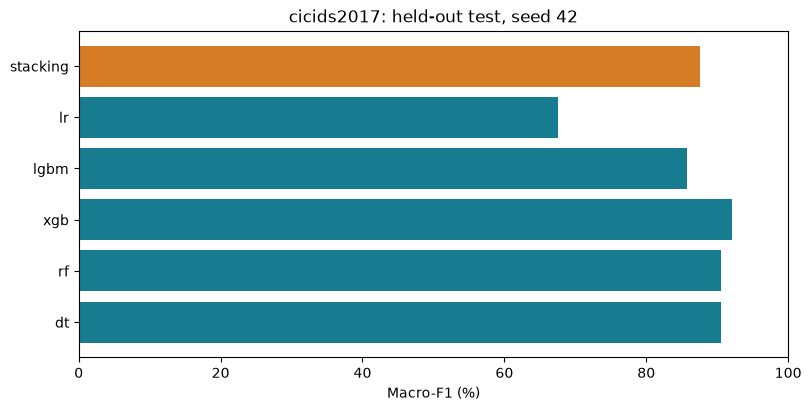

,precision,recall,f1-score,support
BENIGN,0.967500,0.974811,0.971142,397.0
Bot,0.994792,0.987080,0.990921,387.0
DDoS,1.000000,1.000000,1.000000,400.0
DoS GoldenEye,1.000000,0.997500,0.998748,400.0
DoS Hulk,0.996700,0.990164,0.993421,305.0
DoS Slowhttptest,0.992167,0.994764,0.993464,382.0
DoS slowloris,0.994536,0.983784,0.989130,370.0
FTP-Patator,0.995614,1.000000,0.997802,227.0
Infiltration,0.777778,1.000000,0.875000,7.0
PortScan,1.000000,0.994949,0.997468,396.0


In [6]:
comparison = pd.read_csv(RESULT / 'comparison.csv', index_col='model')
display(comparison[['accuracy', 'macro_f1', 'weighted_f1', 'benign_false_positive_rate', 'attack_false_negative_rate']])
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
values = comparison['macro_f1'] * 100
ax.barh(values.index, values, color=['#d77c26' if n == 'stacking' else '#187c91' for n in values.index])
ax.set(xlim=(0, 100), xlabel='Macro-F1 (%)', title=f'{DATASET}: held-out test, seed {SEED}')
plt.show()
report = read_json(RESULT / 'report_stacking.json')['classification_report']
display(pd.DataFrame({label: row for label, row in report.items() if isinstance(row, dict) and label in protocol['split_class_counts']['test']}).T)

## 6. Tái lập và đánh giá model đã lưu

`check_model.py` so với ExpectedPrediction. `evaluate_model.py` so với Label/GroundTruth. Hai khái niệm khác nhau. Cell cuối chỉ in lệnh, không tự chạy hoặc ghi thêm kết quả. Chạy trong PowerShell từ thư mục gốc; đổi --out nếu đã dùng. Model CSV test vẫn chưa chứng minh extractor live tương đương dataset hoặc đo độ chính xác trên Kali.

In [7]:
relative = RESULT.relative_to(ROOT).as_posix()
print(fr'.\.venv\Scripts\python.exe src/check_model.py --model {relative}/models/stacking_ids.joblib --csv {relative}/smoke_test.csv')
print(fr'.\.venv\Scripts\python.exe src/evaluate_model.py --model {relative}/models/stacking_ids.joblib --csv {relative}/splits/test.csv --out experiments/evaluate-{DATASET}-new')

.\.venv\Scripts\python.exe src/check_model.py --model experiments/completion-20261110/multiclass-search-cicids2017-seed42/models/stacking_ids.joblib --csv experiments/completion-20261110/multiclass-search-cicids2017-seed42/smoke_test.csv
.\.venv\Scripts\python.exe src/evaluate_model.py --model experiments/completion-20261110/multiclass-search-cicids2017-seed42/models/stacking_ids.joblib --csv experiments/completion-20261110/multiclass-search-cicids2017-seed42/splits/test.csv --out experiments/evaluate-cicids2017-new
